## Example of mid-point arbitrage

Columns Index(['spot', 'spot_prev', 'date', 'ticker', 'call_symbol', 'put_symbol',
       'call_opt_id', 'put_opt_id', 'is_american', 'is_am', 'expiry', 'strike',
       'fwd_ref', 'df', 'mkt_call_bid', 'mkt_put_bid', 'mkt_call_ask',
       'mkt_put_ask', 'mkt_call_log_volume', 'mkt_put_log_volume',
       'mkt_call_log_open_interest', 'mkt_put_log_open_interest', 'expiry_id',
       'bdte', 'tte_y', 'fwd', 'nms', 'call_ask', 'call_bid', 'ask_vol',
       'bid_vol', 'log_volume', 'log_open_interest', 'pure_strike',
       'pure_ask_price', 'pure_bid_price', 'pure_ask_delta', 'pure_bid_delta',
       'pure_ask_gamma', 'pure_bid_gamma', 'pure_bid_vega', 'pure_ask_vega',
       'pure_bid_theta', 'pure_ask_theta', 'pure_ask_dk', 'pure_bid_dk'],
      dtype='object')


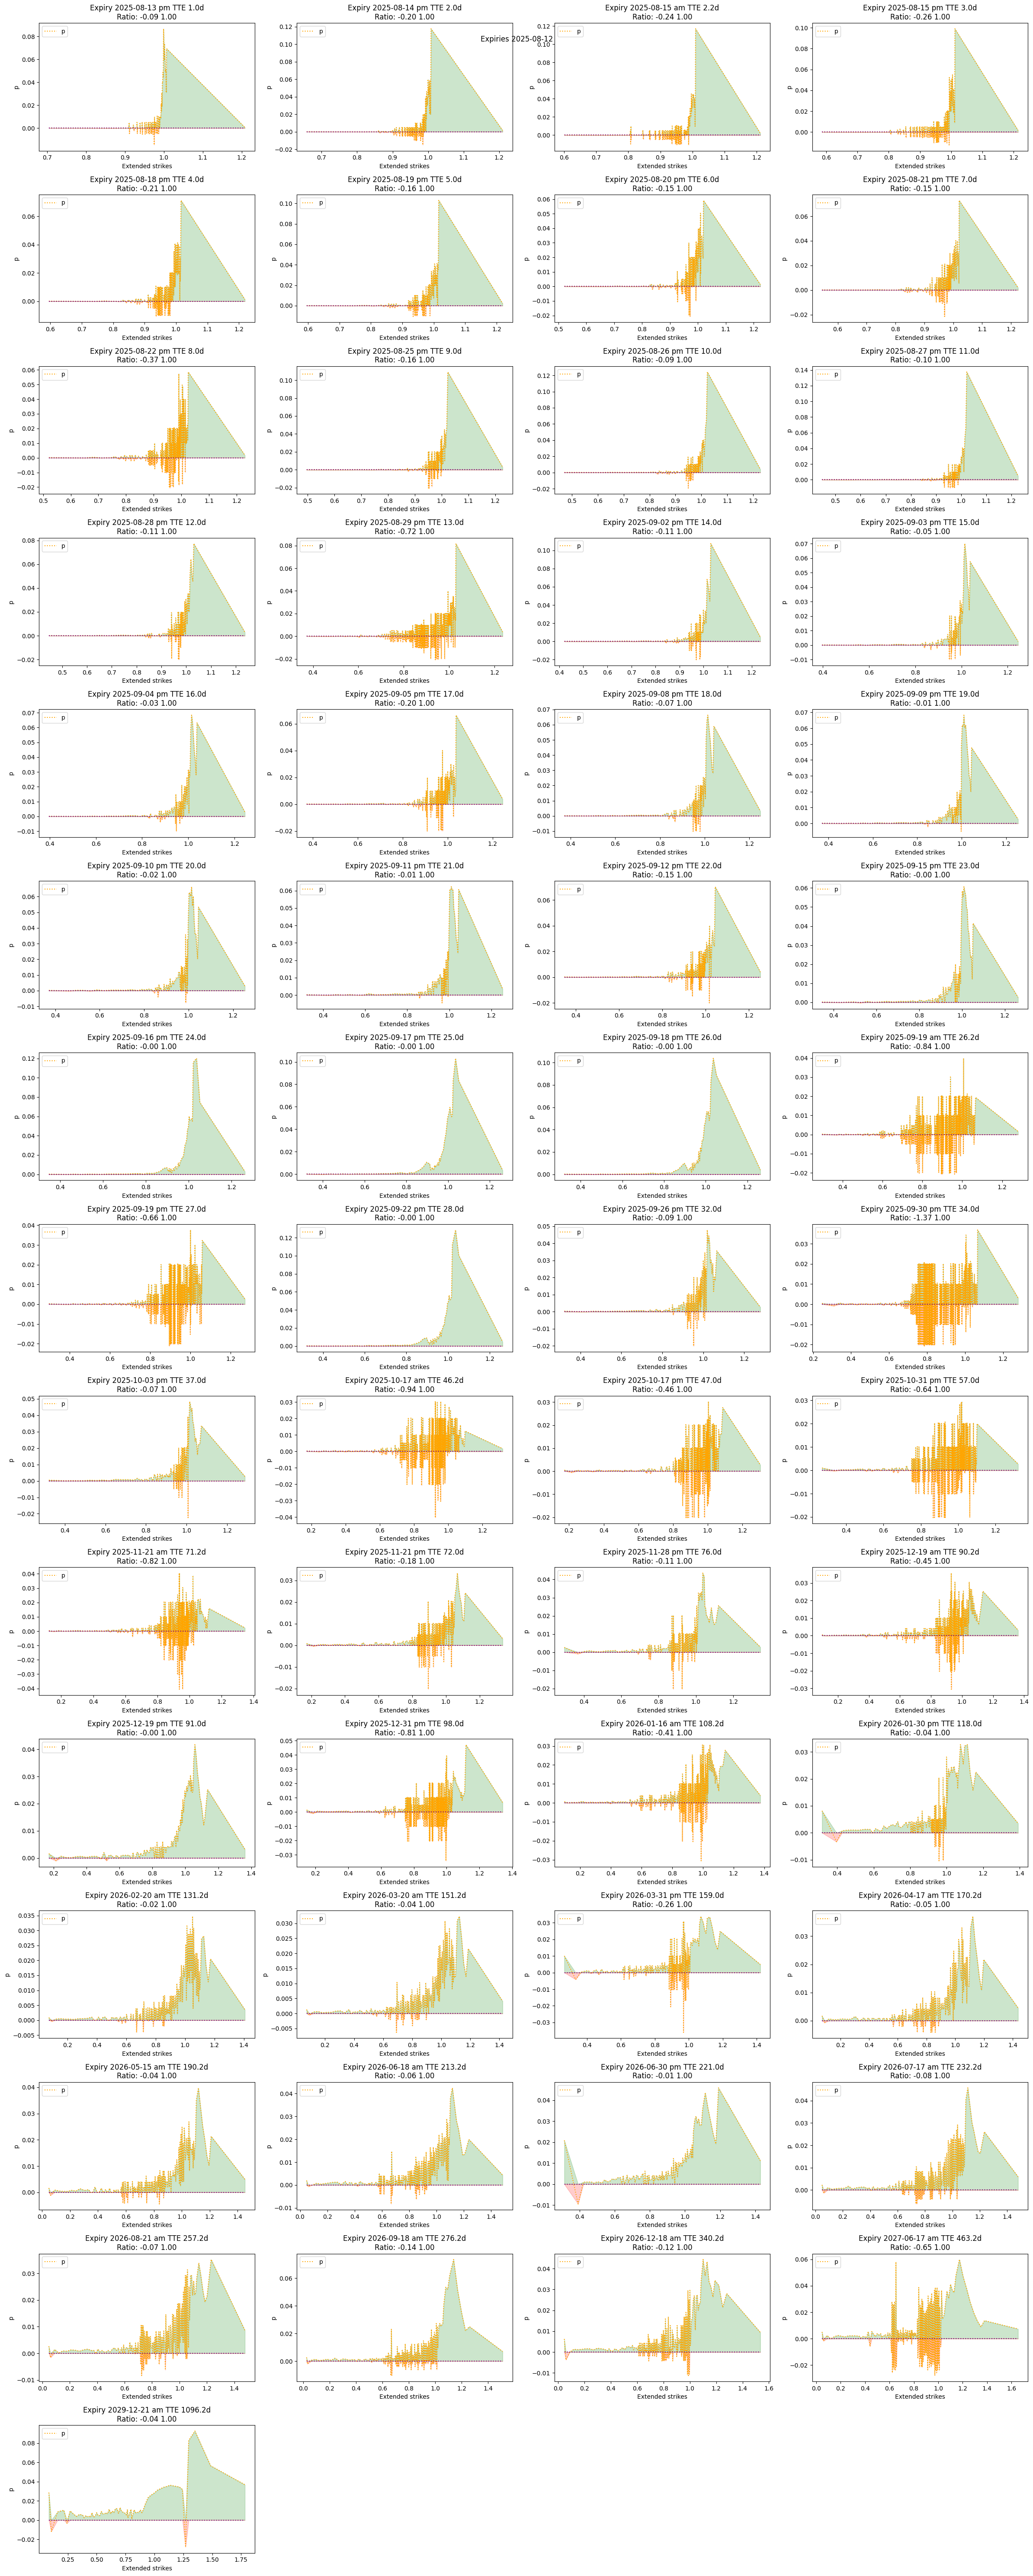

In [1]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2025, 8, 10), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad_day=False)
    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)

    print("Columns", enr_day.columns)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )
    with figure(f"Expiries {d}", row_size=4, col_size=6, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]
            expiry = enr_day['expiry'][ expiry_ids == uid ].iloc[0]
            is_am = enr_day['is_am'][ expiry_ids == uid ].iloc[0]

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()
            mids = ( bids+asks )/2.

            strikesx = np.zeros((len(strikes)+2,), dtype=strikes.dtype)
            strikesx[1:-1] = strikes
            strikesx[0]    = strikes[0]*0.8
            strikesx[-1]   = strikes[-1]*1.2
            midx       = np.zeros_like(strikesx)
            midx[1:-1] = mids
            midx[0]    = 1.- strikesx[0]
            midx[-1]   = 0.

            dCdCK  = np.diff(midx,prepend=1.) / np.diff(strikesx,prepend=0.)
            p      = np.diff(dCdCK,append=0.) 
            ratio  = np.sum(p[p<0.])
            total  = np.sum(p)

            ax = fig.add_subplot(f"Expiry {expiry.date()} {'am' if is_am else 'pm'} TTE {tte_y*DAYS_PER_YEAR:.1f}d\nRatio: {ratio:.2f} {total:.2f}")
            ax.set_xlabel("Extended strikes")
            ax.plot(strikesx, p, ":", label="p", color="orange")
            ax.fill_between(strikesx, p*0., np.clip(p, 0., None), color="green", alpha=0.2)
            ax.fill_between(strikesx, np.clip(p,min=None,max=0.), p*0., color="red", alpha=0.2)
            ax.plot(strikesx, p*0., ":", color="purple")
            ax.set_ylabel("p")
            ax.legend(loc="upper left")
#            ax2 = ax.twinx()
#            ax.plot(strikesx, dCdCK, ".-", label=r"-1 <= dC <= 1", color="blue", alpha=0.2)
 #           ax2.plot(strikesx, dCdCK*0., ":", color="lightblue")
 #           ax2.plot(strikesx, dCdCK*0.+1, ":", color="lightblue")
 #           ax2.set_ylabel("dC/dK")
#            ax2.legend(loc="upper right")


_ = test()